# Thinking Linear Regression ("Deep SLR"): research notebook

**Authors:** Devanik Debnath and Xylia (equal contribution)

This notebook reproduces the paper's analysis. It runs the closed-form checks, the mechanism
demo, the toy and real-data experiments (loaded from `results/`, generated by `scripts/run_all.py`),
and the figures. Everything is deterministic given the seeds.

**Honest scope.** This is a stress test of a simple inference-time rule, not a claim that it beats
established methods. The most important results are the negative ones.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "deep_slr").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from deep_slr import ThinkingLinearRegression as TLR
from deep_slr.baselines import OLS
from deep_slr.data import TOYS, REAL, toy_split, real_split
pd.set_option("display.width", 200)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.0.6


## 1. The method in one formula

Let `y0 = w x + b` be the OLS prediction. The critic measures how far `x` lies outside the training
support, `v(x) = dist(x, [x_min, x_max]) / sd(x_train)`, and sets a gain `a = 1 - exp(-kappa v)`.
The loop moves the prediction toward a boundary anchor `A(x)` for `T` steps:

$$y_{t+1} = y_t + \eta\, a(x)\,(A(x) - y_t), \qquad y_T = A + (1-\eta a)^T (y_0 - A).$$

Inside the support `v = 0`, so the loop is a no-op. Below we check this numerically.

In [2]:
rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 150); y = 3 * x - 2 + rng.normal(0, 1, 150)
xin = rng.uniform(x.min(), x.max(), 1000)
print("max |TLR - OLS| inside realised support:",
      max(np.max(np.abs(TLR(thought_steps=T, anchor=a, eta=0.7, kappa=2.0).fit(x, y).predict(xin)
                        - OLS().fit(x, y).predict(xin)))
          for T in (1, 5, 30) for a in ("extrap", "residual")))
ok = True
for kappa in (0.5, 2.0, np.inf):
    for T in (1, 3, 17):
        m = TLR(thought_steps=T, eta=0.25, kappa=kappa, gamma=0.4).fit(x, y)
        xs = np.linspace(-6, 18, 400)
        ok &= np.allclose(m.predict(xs), m.predict_iterative(xs), atol=1e-10)
print("closed form equals explicit loop for all tested settings:", ok)

max |TLR - OLS| inside realised support: 8.881784197001252e-16
closed form equals explicit loop for all tested settings: True


## 2. Mechanism: one extrapolated input, step by step

The trajectory converges to the anchor. The speed of convergence is set by `eta * kappa * T`.

x=14: v=1.34, gain a=0.738, anchor A=30.940, OLS y0=39.984, final y_T=30.940


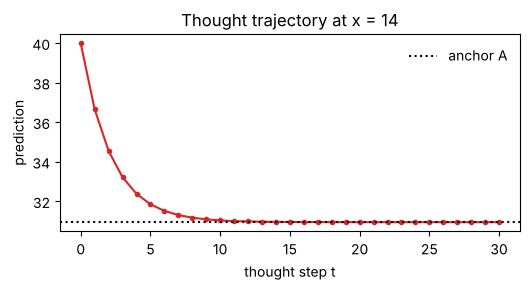

In [3]:
m = TLR(thought_steps=30, eta=0.5, kappa=1.0, gamma=0.3).fit(x, y)
traj, A, v, a = m.trace(14.0)
print(f"x=14: v={v:.2f}, gain a={a:.3f}, anchor A={A:.3f}, OLS y0={traj[0]:.3f}, final y_T={traj[-1]:.3f}")
fig, ax = plt.subplots(figsize=(5.4, 3))
ax.plot(traj, "o-", ms=3, color="#d62728"); ax.axhline(A, ls=":", color="k", label="anchor A")
ax.set(xlabel="thought step t", ylabel="prediction", title="Thought trajectory at x = 14")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 3. Boundary-layer width (a derived prediction, checked numerically)

For small gains, `1-(1-eta a)^T ~ 1 - exp(-T eta kappa v)`. So the weight on the anchor rises from 0 to 1
over a length of about `sd(x)/(T eta kappa)` just outside the support. More thinking makes the transition
sharper, not smoother.

In [4]:
s = toy_split("saturating", 0)
m = TLR(thought_steps=30, eta=1.0, kappa=4.0, gamma=0.25).fit(s["xtr"], s["ytr"])
eps = np.array([0.001, 0.005, 0.01, 0.02])
x_edge = m.x_min_ - eps
y0 = m.b_ + m.w_ * x_edge
_, A_e, _, _ = m.critic(x_edge)
observed_w = (y0 - m.predict(x_edge)) / (y0 - A_e)
predicted_w = 1 - np.exp(-m.thought_steps * m.eta * m.kappa * (m.x_min_ - x_edge) / m.sd_x_)
print(pd.DataFrame({"distance outside edge": eps, "observed weight": observed_w.round(4),
                    "predicted 1-exp(-T eta kappa v)": predicted_w.round(4)}).to_string(index=False))

 distance outside edge  observed weight  predicted 1-exp(-T eta kappa v)
                 0.001           0.0522                           0.0522
                 0.005           0.2352                           0.2352
                 0.010           0.4151                           0.4151
                 0.020           0.6579                           0.6579


## 4. Toy datasets with known ground truth

Each toy has a noise-free `f(x)`, so error is measured against the true conditional mean.

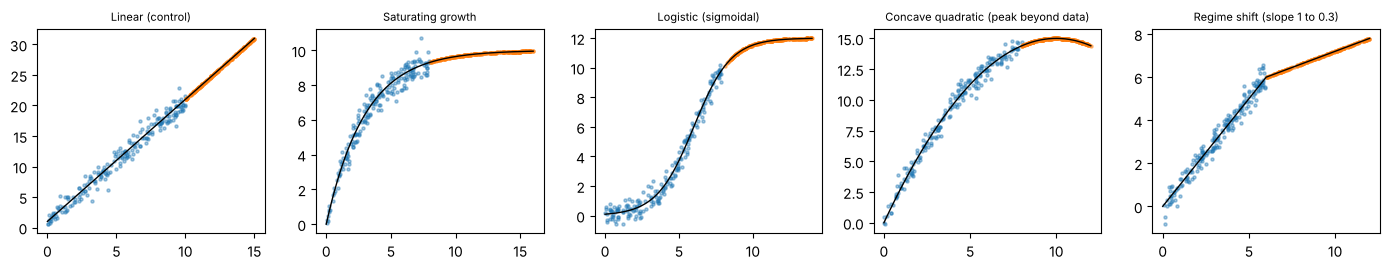

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(14, 2.8))
for ax, (name, spec) in zip(axes, TOYS.items()):
    d = toy_split(name, 0)
    xs = np.linspace(spec["train"][0], spec["ext"][1], 300)
    ax.scatter(d["xtr"], d["ytr"], s=5, alpha=.4, color="#1f77b4")
    ax.scatter(d["xext"], d["yext"], s=5, alpha=.5, color="#ff7f0e")
    ax.plot(xs, spec["f"](xs), "k", lw=1)
    ax.set_title(spec["title"], fontsize=8)
fig.tight_layout(); plt.show()

## 5. Real datasets

Engel curve (income to food expenditure) and diabetes progression vs BMI. Both are bundled offline.

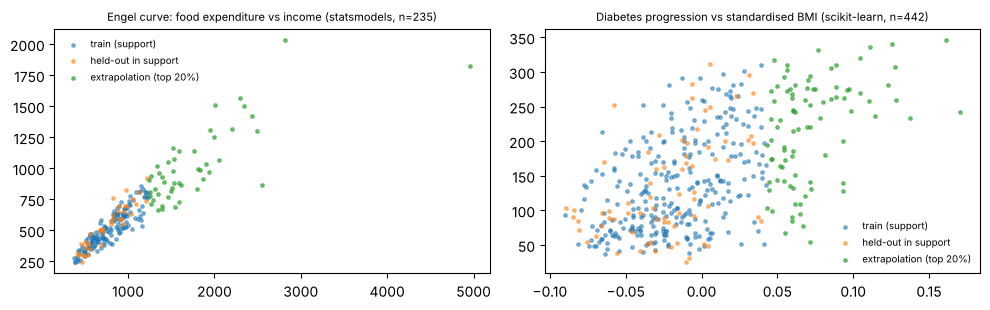

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, name in zip(axes, REAL):
    d = real_split(name, 0)
    ax.scatter(d["xtr"], d["ytr"], s=6, alpha=.5, label="train (support)")
    ax.scatter(d["xin"], d["yin"], s=6, alpha=.5, label="held-out in support")
    ax.scatter(d["xext"], d["yext"], s=6, alpha=.6, label="extrapolation (top 20%)")
    ax.set_title(REAL[name], fontsize=8); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()

## 6. Results: extrapolation error (loaded from the full 30-seed run)

Lower is better. Values are mean and standard deviation over 30 seeds. Hyperparameters were tuned per seed
on a simulated shift inside the training data, never on the extrapolation test set.

In [7]:
main = pd.read_csv(ROOT / "results" / "main_results.csv")
tbl = (main.groupby(["dataset", "method"])["rmse_ext"].agg(["mean", "std"]).round(3))
tbl.unstack("method")["mean"].T.round(3)

dataset,concave,diabetes_bmi,engel,linear,logistic,regime_shift,saturating
method,,,,,,,
Clipped OLS,0.385,67.567,318.163,4.895,1.392,0.792,0.639
GPR,0.645,97.553,333.228,1.548,3.758,1.779,1.819
Huber,5.358,67.494,274.542,0.127,2.238,2.422,5.352
OLS,5.292,67.734,258.301,0.115,2.118,2.418,5.627
Quadratic,0.200,81.094,249.402,0.403,12.548,2.388,6.482
"TLR (extrap, tuned)",1.744,73.026,224.974,0.546,2.989,2.235,1.051
"TLR (residual, tuned)",4.057,68.635,257.031,0.197,2.989,2.413,4.572
TLR binary critic,1.695,73.176,224.468,0.526,2.989,2.301,1.004
TLR one-shot (T=1),1.376,72.939,224.264,0.544,2.995,2.251,0.827


### Paired comparison to OLS

Mean difference (negative means better than OLS), bootstrap 95% CI, fraction of seeds where the method
beats OLS, and Holm-adjusted Wilcoxon p-values.

In [8]:
st = pd.read_csv(ROOT / "results" / "statistics.csv")
show = st[(st.metric == "rmse_ext") & (st.method.str.contains("TLR") | st.method.isin(["kNN (k=10)", "Clipped OLS"]))]
show[["dataset", "method", "mean_diff", "ci_lo", "ci_hi", "rel_change_pct", "win_rate", "p_holm"]].round(4)

,dataset,method,mean_diff,ci_lo,ci_hi,rel_change_pct,win_rate,p_holm
0,concave,Clipped OLS,-4.9066,-5.0149,-4.7978,-92.7193,1.0000,0.0000
4,concave,"TLR (extrap, tuned)",-3.5480,-3.6998,-3.4195,-67.0450,1.0000,0.0000
5,concave,"TLR (residual, tuned)",-1.2349,-1.2917,-1.1796,-23.3351,1.0000,0.0000
6,concave,TLR binary critic,-3.5973,-3.7490,-3.4509,-67.9764,1.0000,0.0000
7,concave,TLR one-shot (T=1),-3.9161,-4.1305,-3.6980,-74.0020,1.0000,0.0000
8,concave,kNN (k=10),-4.7063,-4.8180,-4.5889,-88.9339,1.0000,0.0000
9,diabetes_bmi,Clipped OLS,-0.1667,-0.1928,-0.1383,-0.2461,0.9333,0.0000
13,diabetes_bmi,"TLR (extrap, tuned)",5.2920,2.7050,8.2200,7.8129,0.3333,0.0069
14,diabetes_bmi,"TLR (residual, tuned)",0.9014,0.1769,1.7331,1.3309,0.4333,0.1142
15,diabetes_bmi,TLR binary critic,5.4424,2.8178,8.4526,8.0350,0.3333,0.0069


### In-support identity

The table below shows, for every dataset, the largest difference between TLR and OLS on test points inside the
realised training range. It should be at the level of floating-point error.

In [9]:
idn = main[main.method == "TLR (extrap, tuned)"].groupby("dataset")["max_abs_in_diff_vs_ols"].max()
pd.DataFrame({"max |TLR-OLS| inside support": idn.map(lambda z: f"{z:.2e}")})

,max |TLR-OLS| inside support
dataset,
concave,1.78e-15
diabetes_bmi,0.00e+00
engel,0.00e+00
linear,1.78e-15
logistic,2.22e-16
regime_shift,8.88e-16
saturating,1.78e-15


## 7. Thinking budget and the one-step puzzle

Does more thinking help out of sample? The one-shot variant (`T = 1`, fully tuned) matches or beats the
iterative version on the tasks we tested.

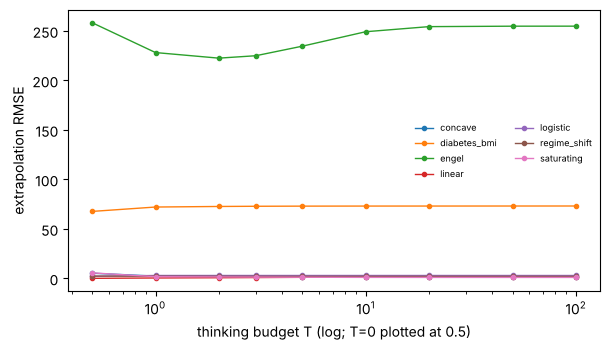

,one-shot (T=1),iterative (T tuned)
dataset,,
concave,1.376,1.744
diabetes_bmi,72.939,73.026
engel,224.264,224.974
linear,0.544,0.546
logistic,2.995,2.989
regime_shift,2.251,2.235
saturating,0.827,1.051


In [10]:
bud = pd.read_csv(ROOT / "results" / "budget_curves.csv")
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for ds, g in bud.groupby("dataset"):
    ax.plot(np.maximum(g["T"], .5), g["mean"], "o-", ms=3, lw=1, label=ds)
ax.set_xscale("log"); ax.set_xlabel("thinking budget T (log; T=0 plotted at 0.5)")
ax.set_ylabel("extrapolation RMSE"); ax.legend(frameon=False, fontsize=6.5, ncol=2)
fig.tight_layout(); plt.show()
one = main[main.method == "TLR one-shot (T=1)"].groupby("dataset")["rmse_ext"].mean()
full = main[main.method == "TLR (extrap, tuned)"].groupby("dataset")["rmse_ext"].mean()
pd.DataFrame({"one-shot (T=1)": one.round(3), "iterative (T tuned)": full.round(3)})

## 8. What drives the gain? A sensitivity map

On the saturating toy, the error is governed mainly by `gamma`, the amount of global slope carried into
the anchor. Flattening (`gamma = 0`) is best; carrying the slope is clearly worse.

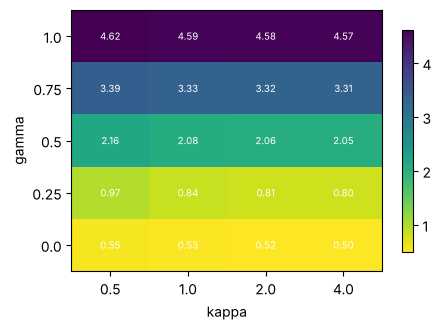

In [11]:
hm = pd.read_csv(ROOT / "results" / "heatmap_gamma_kappa.csv").pivot(index="gamma", columns="kappa", values="rmse_ext")
fig, ax = plt.subplots(figsize=(4.8, 3.4))
im = ax.imshow(hm.values, origin="lower", cmap="viridis_r", aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns)
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
ax.set_xlabel("kappa"); ax.set_ylabel("gamma"); fig.colorbar(im, ax=ax, shrink=.85)
fig.tight_layout(); plt.show()

## 9. Figures from the paper (generated by `scripts/run_all.py`)

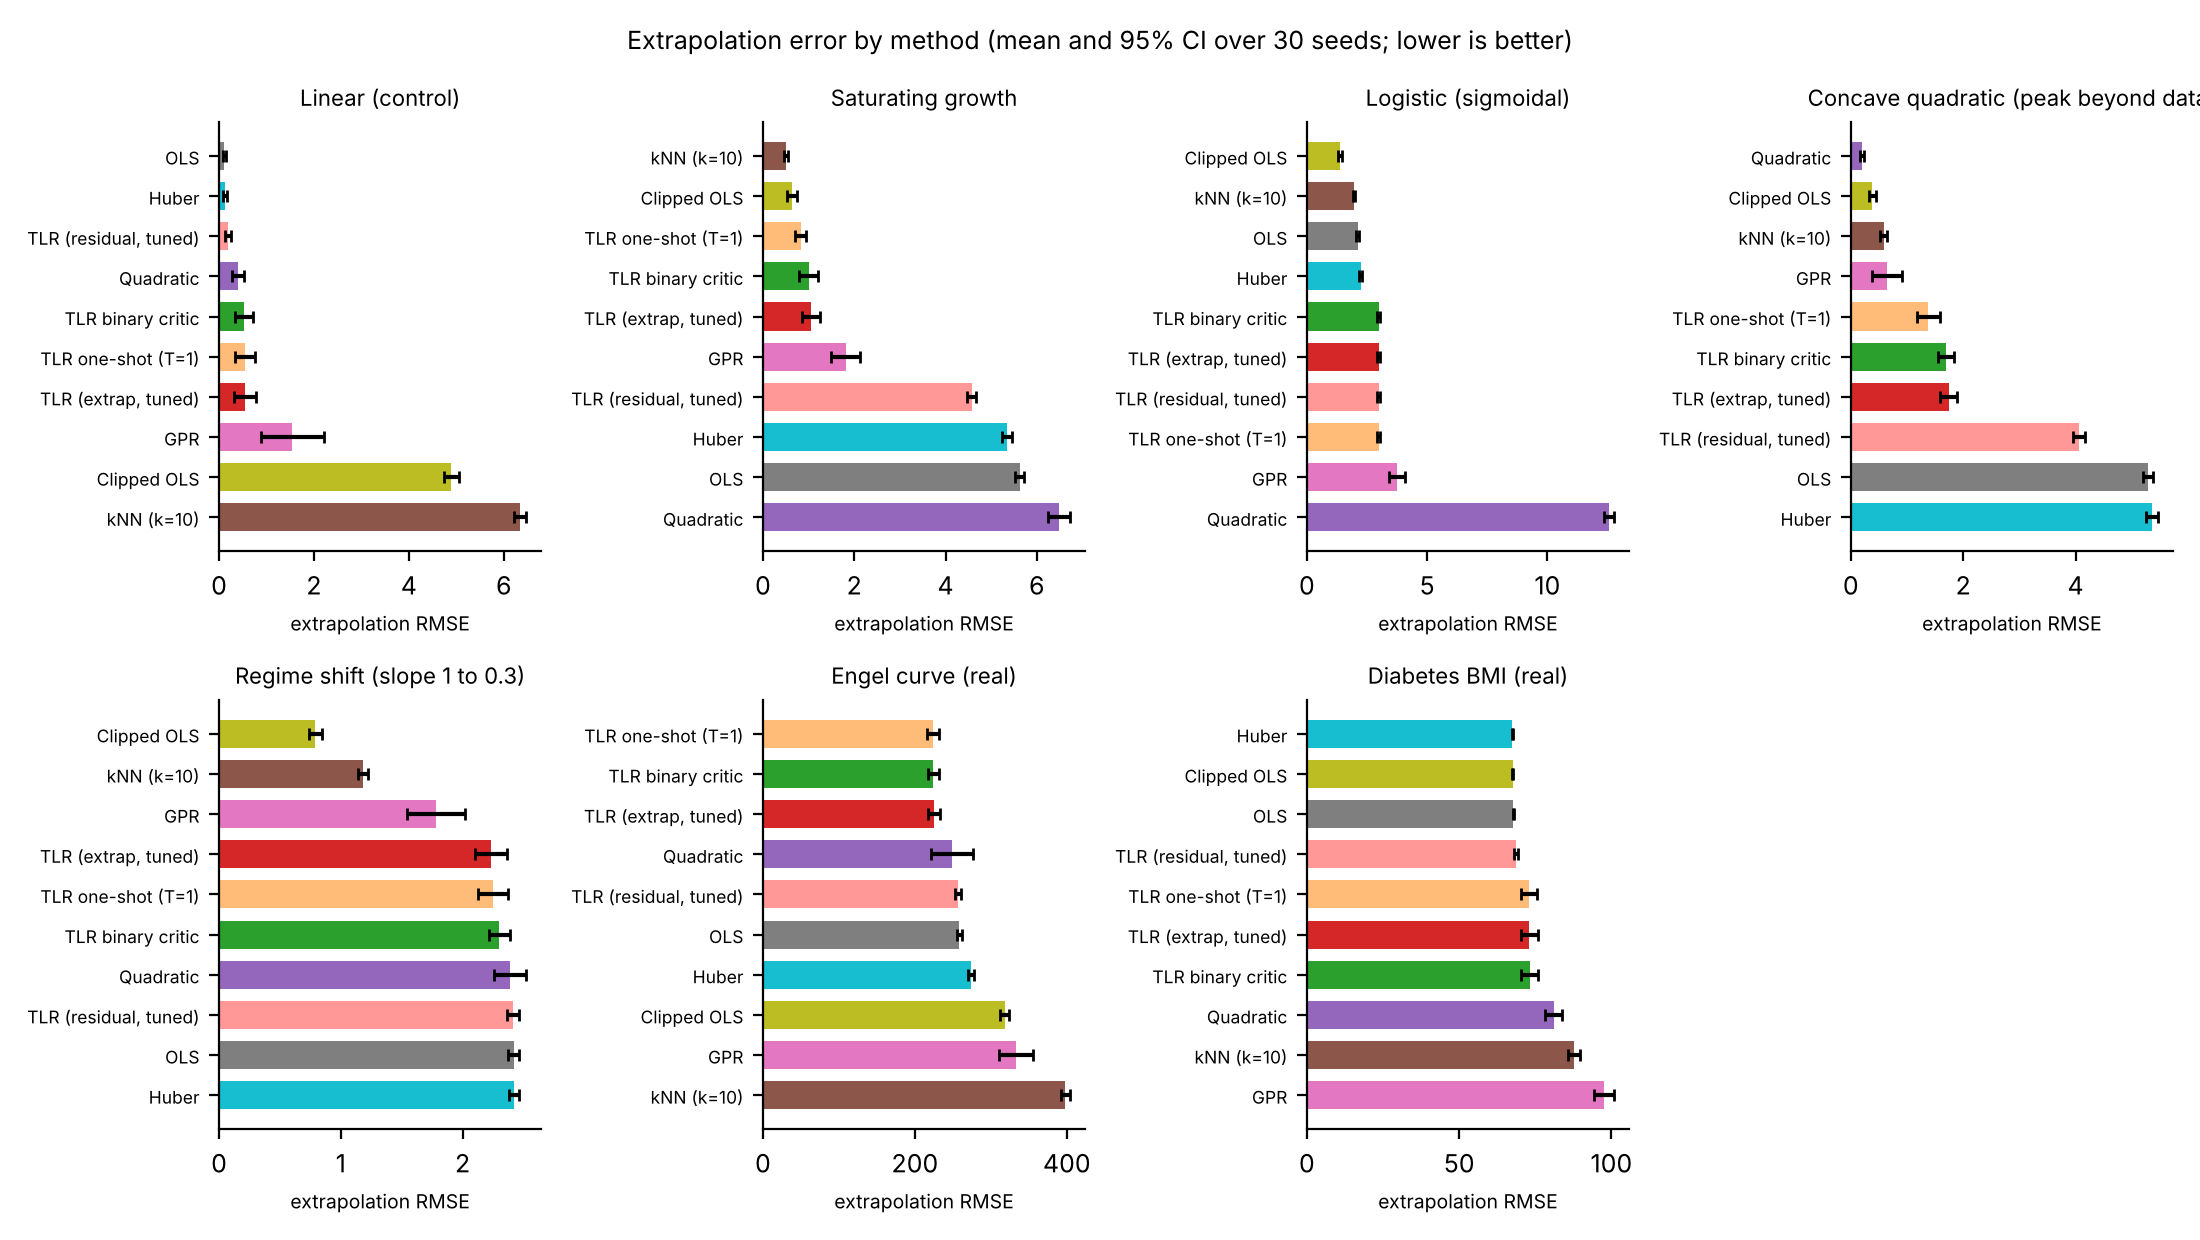

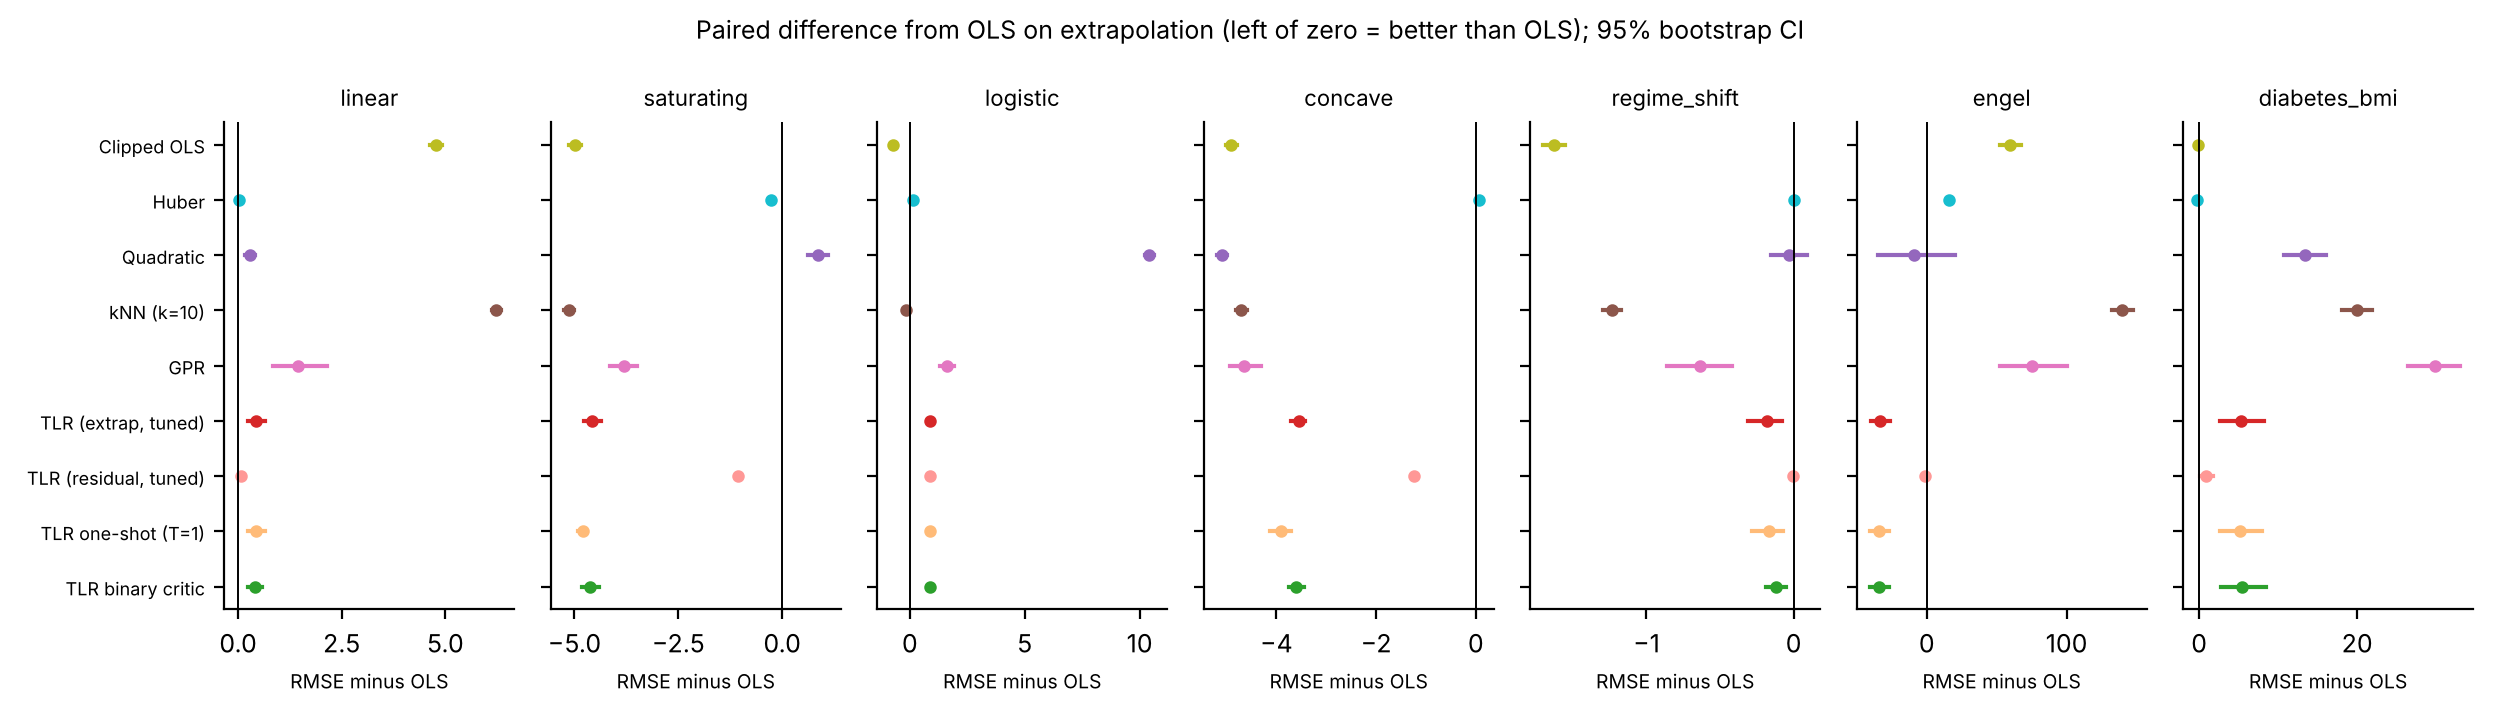

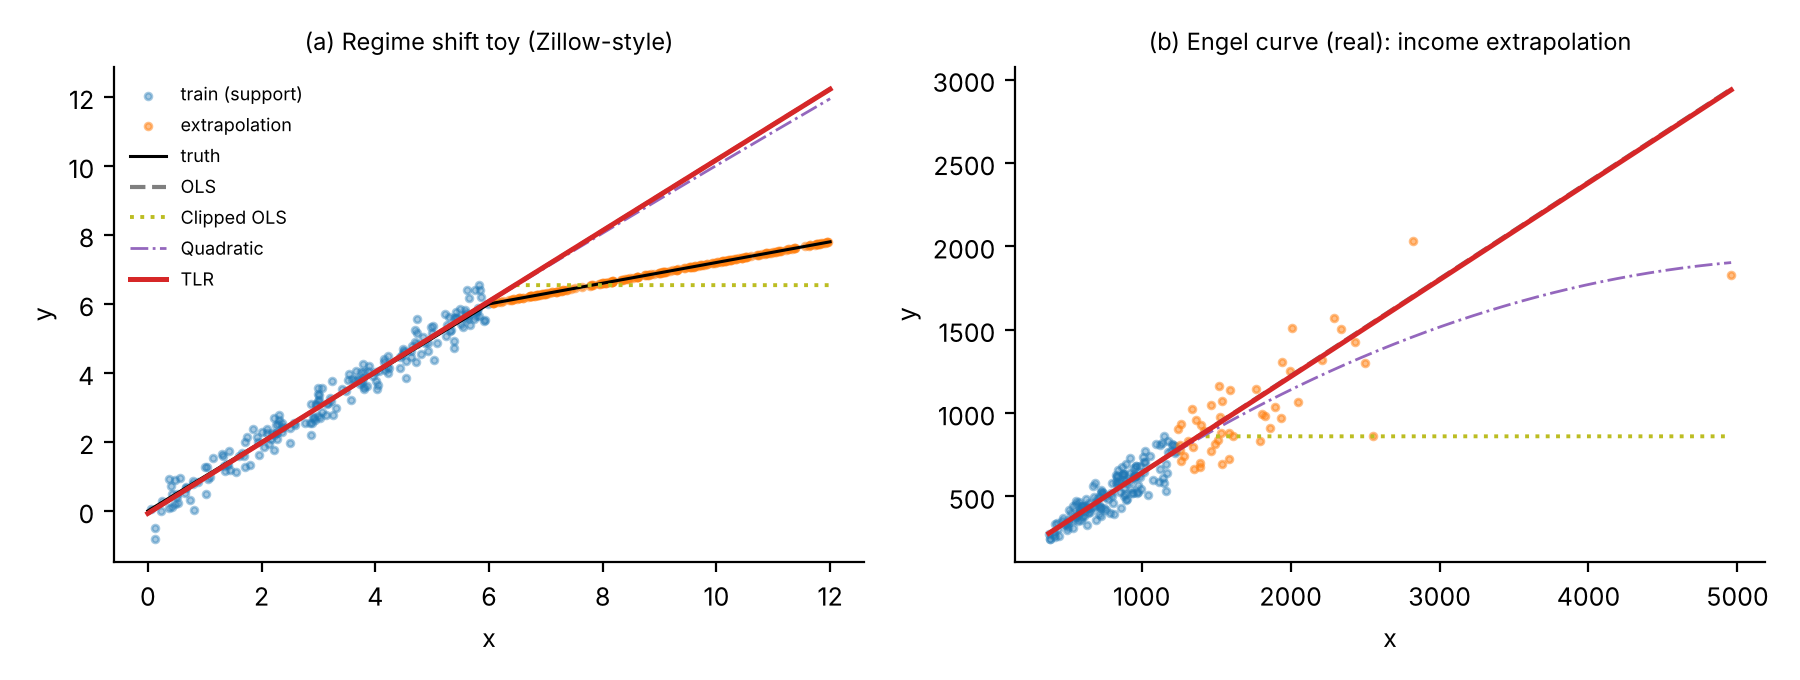

In [12]:
for f in ["fig3_benchmark.png", "fig4_forest_vs_ols.png", "fig7_shift_cases.png"]:
    display(Image(filename=str(ROOT / "figures" / f), width=880))

## 10. Limitations and what the notebook does not show

- Toy families are stylised. Only two real datasets, both one-dimensional, and only bundled data (no network).
- Univariate inputs only. The support test and the anchor are defined for one feature.
- Nested tuning uses only the training support, so it cannot see a regime change beyond the data (Section 7 of the paper).
- The Engel result is the only real-data win, and it is one dataset.
- We did not run a systematic literature search. Novelty claims must be checked against the literature before publication.